# LangGraph 기반 RAG - Step 2. 문서 평가 + 질문 재작성 루프 (Corrective RAG)
##  인공지능기본법 QA

> Corrective RAG(CRAG): 검색 결과를 평가해 나쁘면 교정 동작  

기본 RAG(`retrieve → generate`, [1-1.basic_rag.ipynb](./1-1.basic_rag.ipynb) 참고)는 검색 결과가 엉뚱해도 그대로 답변한다.
이번 실습에서는 그래프가 **스스로 판단**하게 만든다.

- `grade_documents`: LLM이 각 조문의 질문 관련성을 `yes/no`로 평가해 관련 조문만 남김
- **조건부 Edge**: 관련 조문이 없으면 `rewrite_query`로 질문을 법률 용어로 고쳐 다시 검색 (최대 `MAX_REWRITES`회)
- 끝까지 근거가 없으면 지어내지 않고 "근거를 찾지 못했다"고 답변

```mermaid
flowchart TD
    START([START]) --> retrieve[retrieve]
    retrieve --> grade[grade_documents]
    grade -->|관련 조문 있음| generate[generate]
    generate --> END1([END])
    grade -->|없음 & 재시도 소진| no_evidence[no_evidence]
    no_evidence --> END1
    grade -->|없음 & 재시도 가능| rewrite[rewrite_query]
    rewrite --> retrieve

```

> 사전 조건: Qdrant 실행 중(`cd docker-qdrant && docker compose up -d`) + 색인 완료(`uv run python -m rag.indexer`)
>
> 다음 실습: [1-3.agentic_rag.ipynb](./1-3.agentic_rag.ipynb) (질문 라우팅 + 답변 근거 검증)

## 0. 환경 설정

In [11]:
from typing import Literal, TypedDict

from IPython.display import Image, Markdown, display
from langchain_core.caches import InMemoryCache
from langchain_core.globals import set_llm_cache
from langchain_core.messages import HumanMessage, SystemMessage
from langgraph.graph import END, START, StateGraph
from pydantic import BaseModel, Field

from common.ai_model import get_llm_model
from common.config import QDRANT_COLLECTION, RERANK_TOP_N, RETRIEVAL_TOP_K
from common.qdrant import get_qdrant_client
from rag.chunker import format_article_label
from rag.reranker import rerank
from rag.retriever import RetrievedChunk, retrieve

In [12]:
# Qdrant 컬렉션과 색인된 Chunk 수 확인
client = get_qdrant_client()
count = client.count(collection_name=QDRANT_COLLECTION).count # chunk 갯수 count
print(f"컬렉션: {QDRANT_COLLECTION} / Chunk 수: {count}")

컬렉션: ai_basic_law / Chunk 수: 69


In [13]:
# 동일 질문 반복 호출 시 토큰 비용을 아끼기 위한 인메모리 LLM 캐시
# (프로세스 내 캐시이므로 노트북 재시작 시 초기화됨)
set_llm_cache(InMemoryCache())

# 판단(평가ㆍ재작성)용 LLM과 답변 생성용 LLM
judge_llm = get_llm_model(max_tokens=256, model="gpt-5.4-nano")
answer_llm = get_llm_model(max_tokens=1024, model="gpt-5.4-nano")

### 공통 헬퍼

- `search_law`: `rag` 모듈의 **Hybrid 검색(Dense+BM25, RRF) → LLM Rerank**를 한 번에 호출
- `format_context` / `format_sources`: 검색 결과를 LLM 입력용 / 출력용 문자열로 변환
- `show_graph`: 그래프 구조 시각화 (PNG 렌더링 실패 시 Mermaid 텍스트 출력)

In [14]:
def search_law(query: str) -> list[RetrievedChunk]:
    """rag 모듈로 Hybrid 검색 후 Rerank해 상위 N개 조문을 반환한다."""
    candidates = retrieve(query, top_k=RETRIEVAL_TOP_K, use_hybrid=True)
    return rerank(query, candidates, top_n=RERANK_TOP_N)


def format_context(documents: list[RetrievedChunk]) -> str:
    """검색된 조문 텍스트를 LLM context 문자열로 합친다."""
    return "\n\n".join(doc.chunk.text for doc in documents)


def format_sources(documents: list[RetrievedChunk]) -> str:
    """검색된 조문을 '제N조(제목)' 목록 문자열로 만든다."""
    labels = []
    for doc in documents:
        label = format_article_label(doc.chunk.article_no)
        title = f"({doc.chunk.article_title})" if doc.chunk.article_title else ""
        labels.append(f"{label}{title}")
    return ", ".join(dict.fromkeys(labels)) or "(없음)"


def show_graph(graph) -> None:
    """그래프 구조를 PNG로 표시하고, 실패하면 Mermaid 텍스트로 출력한다."""
    try:
        display(Image(graph.get_graph().draw_mermaid_png()))
    except Exception:
        print(graph.get_graph().draw_mermaid())

In [15]:
docs = search_law("고영향 인공지능이란 무엇인가요?")
print("검색 결과:", format_sources(docs))

검색 결과: 제33조(고영향 인공지능의 확인), 제34조(고영향 인공지능과 관련한 사업자의 책무), 제35조(고영향 인공지능 영향평가), 제31조(인공지능 투명성 확보 의무)


### 실행 헬퍼 — `stream`으로 노드 실행 경로 추적

`stream_mode="updates"`를 쓰면 노드가 끝날 때마다 `{노드명: 변경된 State}`가 나와, 그래프가 어떤 경로로 움직였는지 볼 수 있다.

In [16]:
def run(graph, question: str) -> dict:
    """그래프를 stream으로 실행하며 방문한 노드 경로를 출력하고 최종 State를 반환한다."""
    print(f"Q. {question}")
    path, final_state = [], {"question": question}
    for update in graph.stream({"question": question}, stream_mode="updates"):
        for node_name, node_output in update.items():
            path.append(node_name)
            final_state.update(node_output or {})    
            # stram을 통해 path(경로) 변경 연혁 저장. 그래프가 의도대로 분기했는지 눈으로 확인.
    print("경로:", " → ".join(path))
    print("rewrite_count:", final_state.get("rewrite_count", 0)) # retrieve 몇 번 했는지 count
    print("근거 조문:", format_sources(final_state.get("documents", [])))
    display(Markdown(final_state["answer"]))
    return final_state

## Step 1 노드 재사용 — `generate`

In [17]:
ANSWER_SYSTEM_PROMPT = (
    "너는 인공지능기본법 QA 어시스턴트다. 반드시 주어진 <context>의 조문만 근거로 답하라. "
    "답변 끝에 근거 조문(예: 제2조)을 명시하고, context에 없는 내용은 모른다고 답하라."
)

# answer 노드 정의
def generate_node(state) -> dict:
    context = format_context(state["documents"])
    response = answer_llm.invoke([
        SystemMessage(content=ANSWER_SYSTEM_PROMPT),
        HumanMessage(content=f"질문: {state['question']}\n\n<context>\n{context}\n</context>"),
    ])
    return {"answer": response.content}

## State 정의

In [18]:
MAX_REWRITES = 2    # 최대 2번까지 재시도. 즉, 총 3번까지 시도.
NO_EVIDENCE_ANSWER = "인공지능기본법에서 관련 근거 조문을 찾지 못했습니다."

class CorrectiveState(TypedDict):
    question: str          # 사용자 원 질문 (답변 생성에 사용)
    query: str             # 검색에 쓰는 질문 (재작성될 수 있음)
    documents: list[RetrievedChunk]
    rewrite_count: int     # 재검색 카운트 0부터 시작. 2되면 빠져나오도록.
    answer: str

### 구조화 출력(Structured Output)으로 LLM 판단 받기

In [19]:
class RelevanceGrade(BaseModel): # 사용자 정의 output parser
    """조문이 질문에 답하는 데 필요한 정보를 담고 있는지 평가한다."""
    relevant: Literal["yes", "no"] = Field(description="질문과 관련 있으면 yes, 없으면 no")


GRADE_SYSTEM_PROMPT = (
    "너는 법률 검색 결과 평가자다. 조문이 질문에 답하는 데 도움이 되는 내용을 "
    "담고 있으면 yes, 무관하면 no로 평가하라."
)
# STR, JSON, CSV output parser 말고 사용자가 정의한 output parser의 형식에 맞게 결과 구성.
relevance_grader = judge_llm.with_structured_output(RelevanceGrade, method="function_calling")

# 단독 테스트
sample = docs[0]
grade = relevance_grader.invoke([
    SystemMessage(content=GRADE_SYSTEM_PROMPT),
    HumanMessage(content=f"질문: 고영향 인공지능이란?\n\n조문:\n{sample.chunk.text}"),
])
print(format_sources([sample]), "→", grade.relevant)

제33조(고영향 인공지능의 확인) → yes


### 노드 정의

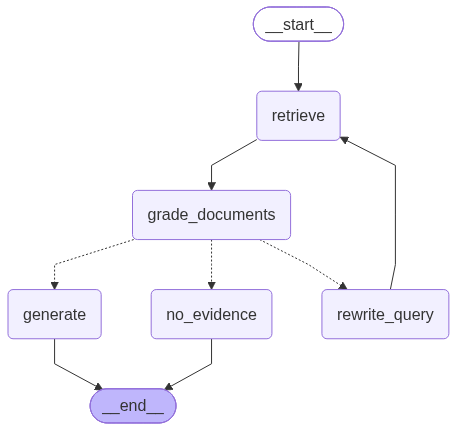

In [ ]:
REWRITE_SYSTEM_PROMPT = (
    "너는 법률 검색 질의 개선 도우미다. 사용자 질문을 인공지능기본법 조문 검색이 잘 되도록 "
    "법률 용어 중심의 한 문장 검색 질의로 다시 써라. 질의 문장만 출력하라."
)

# retrieve로 질문과 관련된 법 조문 Chunk를 Qdrant에서 찾아옴.
def corrective_retrieve_node(state: CorrectiveState) -> dict:
    query = state.get("query") or state["question"] 
    # query는 처음 질문 get("query"), 재시도 state["question"] 두 개를 모두 다 받을 수 있도록 구성
    print(f"  [retrieve] query = {query}")
    return {"query": query, "documents": search_law(query)}

# 질문에 맞는 조문을 retrieve가 찾으면 그것이 얼마나 관련이 있는지 평가하는 node.
def grade_documents_node(state: CorrectiveState) -> dict:
    relevant_docs = []
    for doc in state["documents"]:
        grade = relevance_grader.invoke([   # relevance_grader = LLM. LLM이 관련성 판단
            SystemMessage(content=GRADE_SYSTEM_PROMPT),
            HumanMessage(content=f"질문: {state['question']}\n\n조문:\n{doc.chunk.text}"),
        ])
        # grade.relevant는 조문과 질문의 연관성을 판단하는 최중요 부분.
        # relevance_grader의 with_structured_output(RelevanceGrade, ...) 에서
        # RelevanceGrade의 relevant 필드가 Literal["yes", "no"] 이므로 LLM은 문서와 질문의
        # 관련성을 Yes or No 둘 중 하나로만 판단함. 그로므로 바로 yes 인지를 조건으로 걸 수 있음.
        if grade.relevant == "yes":  # 문서가 질문과 관련성이 있다고 판단시
            relevant_docs.append(doc) # 그걸 append로 추가하여 사용자에게 표시함.
    print(f"  [grade] 관련 조문 {len(relevant_docs)}/{len(state['documents'])}: {format_sources(relevant_docs)}")
    return {"documents": relevant_docs}

# 재시도하는 부분을 함수로 지정.
def rewrite_query_node(state: CorrectiveState) -> dict:
    response = judge_llm.invoke([                       # judge_llm 통해서 rewrite
        SystemMessage(content=REWRITE_SYSTEM_PROMPT),
        HumanMessage(content=state["question"]), # 질문을 invoke로 보내고 결과 받음.
    ])
    # query 정보, count 정보 update. response count는 0 기본, 2번까지만 재시도해야 하므로 tracking함.
    return {"query": response.content.strip(), "rewrite_count": state.get("rewrite_count", 0) + 1}

# 시도 다 해봤지만 관련성 있는 문서 찾지 못한 경우 처리.
def no_evidence_node(state: CorrectiveState) -> dict:
    return {"answer": NO_EVIDENCE_ANSWER} # State만 Update 시킴.

### 조건부 Edge — 다음 노드를 결정하는 함수

`add_conditional_edges`에 넘기는 함수는 State를 보고 **다음에 갈 노드 이름**을 반환한다.

In [20]:
# conditional_edge로 넣을 판단 함수
def decide_after_grading(state: CorrectiveState) -> Literal["generate", "rewrite_query", "no_evidence"]:
    if state["documents"]:
        return "generate"
    if state.get("rewrite_count", 0) < MAX_REWRITES: # 0부터 count, 2번가지 시도
        return "rewrite_query"
    return "no_evidence" # 시도 횟수 다 스면 no_evidence

## 그래프 조립

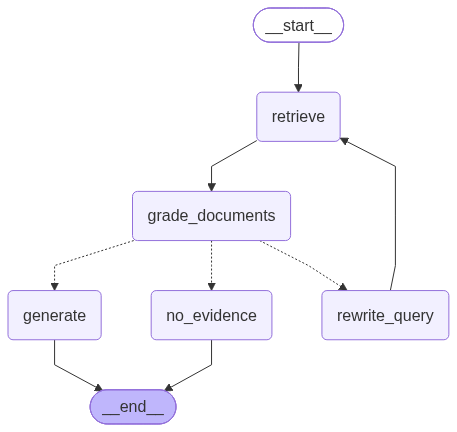

In [ ]:
builder = StateGraph(CorrectiveState)
builder.add_node("retrieve", corrective_retrieve_node)
builder.add_node("grade_documents", grade_documents_node)
builder.add_node("rewrite_query", rewrite_query_node)
builder.add_node("generate", generate_node)  # Step 1의 노드 재사용
builder.add_node("no_evidence", no_evidence_node)

builder.add_edge(START, "retrieve")
builder.add_edge("retrieve", "grade_documents")
builder.add_conditional_edges(
    "grade_documents", 
    decide_after_grading,
    {"rewrite_query" : "rewrite_query", 
    "no_evidence" : "no_evidence",
    "generate" : "generate"
    }
)
builder.add_edge("rewrite_query", "retrieve")
builder.add_edge("generate", END)
builder.add_edge("no_evidence", END)

corrective_graph = builder.compile()
show_graph(corrective_graph)

## 실행

In [13]:
_ = run(corrective_graph, "'고영향 인공지능'이란 무엇인가요?")

Q. '고영향 인공지능'이란 무엇인가요?
  [retrieve] query = '고영향 인공지능'이란 무엇인가요?
  [grade] 관련 조문 4/4: 제2조(정의), 제33조(고영향 인공지능의 확인), 제35조(고영향 인공지능 영향평가), 제34조(고영향 인공지능과 관련한 사업자의 책무)
경로: retrieve → grade_documents → generate
rewrite_count: 0
근거 조문: 제2조(정의), 제33조(고영향 인공지능의 확인), 제35조(고영향 인공지능 영향평가), 제34조(고영향 인공지능과 관련한 사업자의 책무)


'고영향 인공지능'이란 사람의 생명, 신체의 안전 및 기본권에 중대한 영향을 미치거나 위험을 초래할 우려가 있는 인공지능 시스템으로서 특정 영역에서 활용되는 것을 말합니다. 이 특정 영역에는 에너지 공급, 먹는물의 생산 공정, 보건의료 제공, 의료기기 및 디지털 의료기기 개발, 범죄 수사 및 체포 업무를 위한 생체인식정보의 분석, 개인의 권리 및 의무 관계에 중대한 영향을 미치는 판단, 교통안전 관련 시스템, 공공서비스 제공, 교육에서의 학생 평가 등이 포함됩니다. 

근거 조문: 제2조

In [14]:
_ = run(corrective_graph, "AI 기본법에서 고영향 인공지능 사업자가 지켜야 할 책무는?")

Q. AI 기본법에서 고영향 인공지능 사업자가 지켜야 할 책무는?
  [retrieve] query = AI 기본법에서 고영향 인공지능 사업자가 지켜야 할 책무는?
  [grade] 관련 조문 4/4: 제34조(고영향 인공지능과 관련한 사업자의 책무), 제35조(고영향 인공지능 영향평가), 제33조(고영향 인공지능의 확인), 제31조(인공지능 투명성 확보 의무)
경로: retrieve → grade_documents → generate
rewrite_count: 0
근거 조문: 제34조(고영향 인공지능과 관련한 사업자의 책무), 제35조(고영향 인공지능 영향평가), 제33조(고영향 인공지능의 확인), 제31조(인공지능 투명성 확보 의무)


고영향 인공지능 사업자가 지켜야 할 책무는 다음과 같습니다:

1. 위험관리방안의 수립ㆍ운영
2. 인공지능이 도출한 최종결과, 주요 기준, 학습용 데이터의 개요 등에 대한 설명 방안의 수립ㆍ시행
3. 이용자 보호 방안의 수립ㆍ운영
4. 고영향 인공지능에 대한 사람의 관리ㆍ감독
5. 안전성ㆍ신뢰성 확보를 위한 조치의 내용을 확인할 수 있는 문서의 작성과 보관
6. 고영향 인공지능의 안전성ㆍ신뢰성 확보를 위한 위원회에서 심의ㆍ의결된 사항

이러한 조치는 대통령령으로 정하는 바에 따라 이행해야 합니다. (제34조)

In [15]:
# 법 범위 밖 질문: 관련 조문이 없어 재작성 루프를 돌다가 no_evidence로 종료되는지 확인
_ = run(corrective_graph, "자율주행차 사고가 나면 보험금은 얼마나 받나요?")

Q. 자율주행차 사고가 나면 보험금은 얼마나 받나요?
  [retrieve] query = 자율주행차 사고가 나면 보험금은 얼마나 받나요?
  [grade] 관련 조문 0/4: (없음)
  [retrieve] query = 자율주행차 사고 시 보험금 지급 기준은 어떻게 되나요?
  [grade] 관련 조문 0/4: (없음)
  [retrieve] query = 자율주행차 사고 시 보험금 지급 기준은 어떻게 되나요?
  [grade] 관련 조문 0/4: (없음)
경로: retrieve → grade_documents → rewrite_query → retrieve → grade_documents → rewrite_query → retrieve → grade_documents → no_evidence
rewrite_count: 2
근거 조문: (없음)


인공지능기본법에서 관련 근거 조문을 찾지 못했습니다.

In [16]:
# 다른 문제 질문
_ = run(corrective_graph, "파이썬 언어에 대해 설명해줘")

Q. 파이썬 언어에 대해 설명해줘
  [retrieve] query = 파이썬 언어에 대해 설명해줘
  [grade] 관련 조문 0/4: (없음)
  [retrieve] query = 인공지능기본법의 관련 조문을 검색하기 위한 질의: "인공지능기본법의 정의 및 적용 범위에 대한 조문"
  [grade] 관련 조문 0/4: (없음)
  [retrieve] query = 인공지능기본법의 관련 조문을 검색하기 위한 질의: "인공지능기본법의 정의 및 적용 범위에 대한 조문"
  [grade] 관련 조문 0/4: (없음)
경로: retrieve → grade_documents → rewrite_query → retrieve → grade_documents → rewrite_query → retrieve → grade_documents → no_evidence
rewrite_count: 2
근거 조문: (없음)


인공지능기본법에서 관련 근거 조문을 찾지 못했습니다.

---
## 정리

| 핵심 LangGraph 개념 | 재사용한 `rag/` 모듈 |
|---------------------|---------------------|
| `add_conditional_edges`, 루프, `with_structured_output`, `stream` | `retriever.retrieve`, `reranker.rerank`, `chunker.format_article_label` |

**다음 실습**: [1-3.agentic_rag.ipynb](./1-3.agentic_rag.ipynb) — 그래프의 입구(라우팅)와 출구(근거 검증)에 판단 노드를 추가한다.